# 01 – Run 3D structure fusion pipeline (Option A: mallee canopy only)

This notebook demonstrates the **3D fusion of Z_norm LiDAR tiles with 2D structure labels** using the `fvc3dstruct` module.

## Quick Start
1. **Configure site & tile** in Cell 3 (toggle between Site 1 DD0001 / Site 11 DD0011)
2. **Run all cells** to process the pipeline
3. **Inspect outputs** in the final cells

## Pipeline stages:
1. Load sample Z_norm and structure LAS tiles  
2. Build and visualise a simple canopy height model (CHM)  
3. Detect mallee crowns via watershed and visualise crowns  
4. Compute **data-driven height thresholds** for each class (64–68)  
5. Run the **full Option A pipeline** for a single tile:
   - Cartesian voxel merge (25cm XY, 20cm Z)
   - Crown-centric polar refinement (10 radial × 36 angular bins)
   - Height sanity rules (enforce class-specific height bounds)
   - `treeID` assigned **only to high mallee canopy points** (class 68)
6. Inspect final outputs:
   - Class distribution
   - `treeID` histogram
   - 2D scatter preview of mallee crowns

## Data locations:
- **Site 1 (DD0001)**: `/data/calperumResearch/site1_1_DD0001/`
- **Site 11 (DD0011)**: `/data/calperumResearch/site2_1_DD0011/`

In [1]:
# Clear Python cache and force reload of fvc3dstruct modules
import sys
from pathlib import Path

# Add to path
sys.path.insert(0, "/home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class")

# Remove all fvc3dstruct modules from cache
modules_to_remove = [key for key in sys.modules.keys() if key.startswith('fvc3dstruct')]
for mod in modules_to_remove:
    del sys.modules[mod]

print(f"Cleared {len(modules_to_remove)} cached modules")

# Also clear __pycache__ directories
import shutil
base_path = Path("/home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/fvc3dstruct")
for pycache in base_path.rglob("__pycache__"):
    shutil.rmtree(pycache, ignore_errors=True)
    print(f"Removed {pycache}")

print("✅ Module cache cleared - ready for fresh import")


Cleared 0 cached modules
Removed /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/fvc3dstruct/__pycache__
✅ Module cache cleared - ready for fresh import


In [2]:
from pathlib import Path


import laspy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


from fvc3dstruct.height_stats import compute_class_height_thresholds
from fvc3dstruct.watershed import get_mallee_centroids_watershed
from fvc3dstruct.pipeline import process_tile, process_folder


# Base path for this step
BASE = Path("/home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class")


# ========================================
# CONFIGURATION: Site and Tile Selection
# ========================================
# Toggle between sites by commenting/uncommenting blocks below


# --- SITE 1 (DD0001) ---
# SITE_NAME = "site1_DD0001"
# tile_id = "109"  # Options: "109", "110", "111", etc.
# z_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/z_norm/csf/")
# s_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/mask/coreg/icp/")


# --- SITE 11 (DD0011) --- (uncomment to use)
SITE_NAME = "site2_DD0011"
tile_id = "33"  # Options: "109", "110", "111", etc.
z_dir = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf/")
s_dir = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/mask/coreg/icp/")


# ========================================
# Setup paths and check files
# ========================================
# Output folder for this notebook (kept local to notebooks/)
nb_out_dir = BASE / "notebooks" / "outputs"
nb_out_dir.mkdir(parents=True, exist_ok=True)


# Input file patterns
z_path = z_dir / f"z_norm_csf_tiles_multispectral.{tile_id}.las"
s_path = s_dir / f"mask_tiles_multispectral.{tile_id}.las"


# Verification
print("=" * 60)
print(f"SITE: {SITE_NAME}")
print(f"TILE: {tile_id}")
print("=" * 60)
print(f"Z_norm LAS : {z_path}")
print(f"Struct LAS : {s_path}")
print(f"Output dir : {nb_out_dir}")
print("-" * 60)
print(f"Files exist?")
print(f"  Z_norm : {'✅ YES' if z_path.exists() else '❌ NO'}")
print(f"  Struct : {'✅ YES' if s_path.exists() else '❌ NO'}")
print("=" * 60)


if not z_path.exists() or not s_path.exists():
    print("\n⚠️  WARNING: One or both input files not found!")
    print("   Check paths or tile_id above.")

SITE: site2_DD0011
TILE: 33
Z_norm LAS : /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.33.las
Struct LAS : /data/calperumResearch/site2_1_DD0011/lidar/clipped/mask/coreg/icp/mask_tiles_multispectral.33.las
Output dir : /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/notebooks/outputs
------------------------------------------------------------
Files exist?
  Z_norm : ✅ YES
  Struct : ✅ YES


In [3]:
# --- Load LAS tiles ---
las_z = laspy.read(z_path)
las_s = laspy.read(s_path)

print(f"Z_norm points   : {len(las_z.points):,}")
print(f"Structure points: {len(las_s.points):,}")

if "Z_norm" not in las_z.point_format.dimension_names:
    raise RuntimeError("Z_norm LAS is missing 'Z_norm' extra dimension.")

zn = np.asarray(las_z["Z_norm"], dtype=float)
print(f"Z_norm range: {zn.min():.2f} m  →  {zn.max():.2f} m")


Z_norm points   : 1,666,642
Structure points: 542,451
Z_norm range: 0.00 m  →  6.59 m


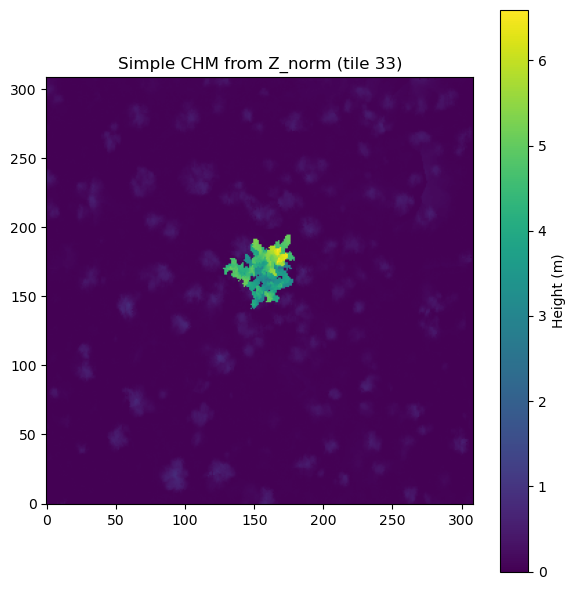

In [4]:
# --- Build a simple CHM from Z_norm points ---
grid_res = 0.10  # 10 cm

x = las_z.x
y = las_z.y

min_x, max_x = float(x.min()), float(x.max())
min_y, max_y = float(y.min()), float(y.max())

nx = int(np.ceil((max_x - min_x) / grid_res)) + 1
ny = int(np.ceil((max_y - min_y) / grid_res)) + 1

ix = ((x - min_x) / grid_res).astype(int)
iy = ((y - min_y) / grid_res).astype(int)
ix = np.clip(ix, 0, nx - 1)
iy = np.clip(iy, 0, ny - 1)

chm = np.zeros((ny, nx), dtype=np.float32)
# max height in each grid cell
for xx, yy, hh in zip(ix, iy, zn):
    if hh > chm[yy, xx]:
        chm[yy, xx] = hh

plt.figure(figsize=(6, 6))
im = plt.imshow(chm, origin="lower", cmap="viridis")
plt.title(f"Simple CHM from Z_norm (tile {tile_id})")
plt.colorbar(im, label="Height (m)")
plt.tight_layout()
plt.show()


→ Auto-derived params: min_tree_dist=0.80 m, smoothing_sigma=1.33 px
🌳 [Watershed] Identified 3 crowns (Z_norm fallback (≥ 1.00m, 21,470 pts)).
Detected 3 crown objects via watershed (min_tree_dist=0.8, smoothing_sigma=1.3333333333333333).

Attempting auto-tune to merge crowns → target 1…
🌳 [Watershed] Identified 3 crowns (Z_norm fallback (≥ 1.00m, 21,470 pts)).
  → Tried min_tree_dist=1.00, smoothing_sigma=1.60: crowns=3
🌳 [Watershed] Identified 1 crowns (Z_norm fallback (≥ 1.00m, 21,470 pts)).
  → Tried min_tree_dist=1.28, smoothing_sigma=2.00: crowns=1
  ✓ Auto-tune found parameters yielding ≤1 crown


/tmp/ipykernel_2935276/2709124723.py:70: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(cx, cy, c="white", edgecolors="k", marker="x", s=40)


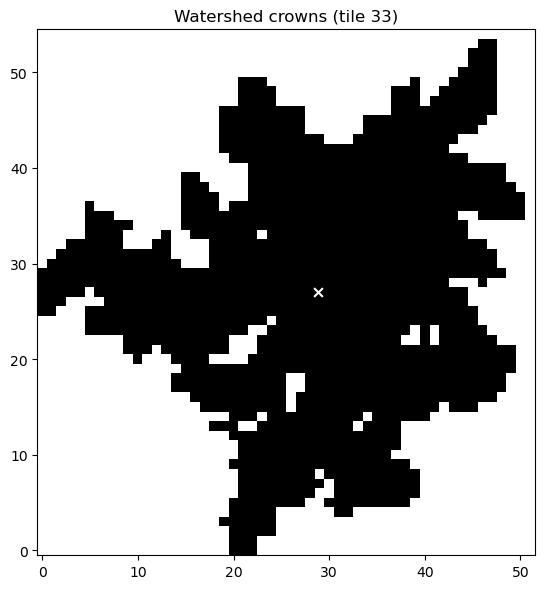


💡 TIP: To use these parameters in the pipeline, add to config:
   "min_tree_dist": 1.2800000000000002,
   "smoothing_sigma": 2.0,


In [5]:
# --- Detect mallee crowns via watershed (Option A core) ---
# Note: These parameters are for exploration only.
# The pipeline uses config values (default: min_tree_dist=0.75m, smoothing_sigma=0.5)

from fvc3dstruct.watershed import auto_watershed_params

# Start with data-driven parameters estimated from canopy spacing
auto_min_dist, auto_sigma = auto_watershed_params(
    las_s=las_s,
    las_z=las_z,
    grid_res=0.10,
    fallback_min_height=1.0,
)
ws_min_tree_dist = float(auto_min_dist)
ws_smoothing_sigma = float(auto_sigma)
print(f"→ Auto-derived params: min_tree_dist={ws_min_tree_dist:.2f} m, smoothing_sigma={ws_smoothing_sigma:.2f} px")

labels, centroids, min_x_ws, min_y_ws = get_mallee_centroids_watershed(
    las_s,
    grid_res=0.10,
    min_tree_dist=ws_min_tree_dist,
    smoothing_sigma=ws_smoothing_sigma,
    fallback_points=(las_z.x, las_z.y, zn),  # use Z_norm geometry as fallback
    fallback_min_height=1.0,
)

n_crowns = int(labels.max())
print(f"Detected {n_crowns} crown objects via watershed (min_tree_dist={ws_min_tree_dist}, smoothing_sigma={ws_smoothing_sigma}).")

# If multiple crowns are detected but you expect a single crown,
# auto-tune around the auto-derived baseline with progressively stronger values.
if n_crowns > 1:
    print("\nAttempting auto-tune to merge crowns → target 1…")
    # Scale up from baseline to encourage merging peaks
    candidates = [
        (ws_min_tree_dist * 1.25, ws_smoothing_sigma * 1.2),
        (ws_min_tree_dist * 1.6,  ws_smoothing_sigma * 1.5),
        (max(ws_min_tree_dist, 2.5), max(ws_smoothing_sigma, 1.6)),
        (max(ws_min_tree_dist, 3.0), max(ws_smoothing_sigma, 2.0)),
    ]
    tuned = False
    for mtd, sigma in candidates:
        labels2, centroids2, min_x_ws2, min_y_ws2 = get_mallee_centroids_watershed(
            las_s,
            grid_res=0.10,
            min_tree_dist=mtd,
            smoothing_sigma=sigma,
            fallback_points=(las_z.x, las_z.y, zn),
            fallback_min_height=1.0,
        )
        n2 = int(labels2.max())
        print(f"  → Tried min_tree_dist={mtd:.2f}, smoothing_sigma={sigma:.2f}: crowns={n2}")
        if n2 <= 1:
            labels, centroids, min_x_ws, min_y_ws = labels2, centroids2, min_x_ws2, min_y_ws2
            ws_min_tree_dist, ws_smoothing_sigma = float(mtd), float(sigma)
            n_crowns = n2
            tuned = True
            print("  ✓ Auto-tune found parameters yielding ≤1 crown")
            break
    if not tuned:
        print("  ⚠️ Auto-tune did not reach a single crown. Consider inspecting CHM/peaks.")

if n_crowns > 0:
    plt.figure(figsize=(6, 6))
    mask = np.ma.masked_where(labels == 0, labels)
    plt.imshow(mask, origin="lower", cmap="nipy_spectral")
    if len(centroids) > 1:
        cx = (centroids[1:, 0] - min_x_ws) / 0.10
        cy = (centroids[1:, 1] - min_y_ws) / 0.10
        plt.scatter(cx, cy, c="white", edgecolors="k", marker="x", s=40)
    plt.title(f"Watershed crowns (tile {tile_id})")
    plt.tight_layout()
    plt.show()
    
    print(f"\n💡 TIP: To use these parameters in the pipeline, add to config:")
    print(f'   "min_tree_dist": {ws_min_tree_dist},')
    print(f'   "smoothing_sigma": {ws_smoothing_sigma},')

In [6]:
# --- Compute data-driven height thresholds per class ---

height_ranges = compute_class_height_thresholds(las_s, las_z)

rows = []
for cls, (low, high) in sorted(height_ranges.items()):
    rows.append({
        "class": cls,
        "low_m": round(low, 2),
        "high_m": round(high, 2),
    })

df_ranges = pd.DataFrame(rows)
df_ranges


  ℹ️ Matched 542,451/542,451 structure pts to Z_norm
  Class 64 (Forb): 0.00–0.03 m (n=198,948)
  Class 65 (Woody Debris): 0.00–4.35 m (n=14,506)
  ⚠️ Class 66 (Hummock): only 0 pts → default (0.0, 0.8)
  Class 67 (Shrub): 0.02–0.23 m (n=302,262)
  ⚠️ Class 68 (Mallee): only 0 pts → default (1.5, 8.0)


,class,low_m,high_m
0,64,0.00,0.03
1,65,0.00,4.35
2,66,0.00,0.80
3,67,0.02,0.23
4,68,1.50,8.00


In [16]:
# ========================================
# Run the full Option A pipeline
# ========================================
# Choose run mode: 'single' or 'folder'
RUN_MODE = 'folder'  # change to 'folder' to process all tiles in z_dir/s_dir

# --- SITE SELECT ---
SITE_NAME = "site2_DD0011"   # ✅ Site 11

# Output directory (toggle based on site)
if SITE_NAME == "site1_DD0001":
    OUTPUT_BASE_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid")
elif SITE_NAME == "site2_DD0011":
    OUTPUT_BASE_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/3d_structure_mask_malleid")
else:
    OUTPUT_BASE_DIR = nb_out_dir  # fallback to notebook outputs

OUTPUT_BASE_DIR.mkdir(parents=True, exist_ok=True)

# Output naming includes site and tile for easy tracking
out_full = None


# Optional config overrides (uncomment to customize)
# Use stronger watershed parameters to merge nearby peaks into one crown
config = {
    # "voxel_size_xy": 0.10,       # XY voxel resolution (default: 0.10m)
    # "voxel_size_z": 0.10,        # Z voxel resolution (default: 0.10m)
    # "r_bin": 0.10,               # Radial bin size (default: 0.10m)
    # "theta_bin_deg": 10.0,       # Angular bin size (default: 10.0 degrees)
    
    # Watershed crown detection parameters:
    # Set numeric values to override auto and encourage single crown
    "min_tree_dist": 2.5,       # in meters; try 2.5 or 3.0
    "smoothing_sigma": 1.6,     # in pixels; try 1.6 or 2.0
}

print(f"Processing mode: {RUN_MODE}")
print("-" * 60)


if RUN_MODE == 'single':
    out_full = OUTPUT_BASE_DIR / f"znorm_3Dlabels_{tile_id}.las"
    print(f"Processing {SITE_NAME} tile {tile_id}...")
    print(f"Output will be saved to: {out_full}")
    print("-" * 60)
    process_tile(
        z_path=z_path,
        s_path=s_path,
        out_path=out_full,
        config=config,
    )
else:
    batch_out_dir = OUTPUT_BASE_DIR
    print(f"Batch processing all matched tiles in:\n  Z: {z_dir}\n  S: {s_dir}")
    print(f"Outputs → {batch_out_dir}")
    
    # Find all matching tile pairs
    z_files = sorted(z_dir.glob("z_norm_csf_tiles_multispectral.*.las"))
    s_files = sorted(s_dir.glob("mask_tiles_multispectral.*.las"))
    
    # Extract tile IDs and match them
    z_tiles = {f.stem.split('.')[-1]: f for f in z_files}
    s_tiles = {f.stem.split('.')[-1]: f for f in s_files}
    common_tiles = sorted(set(z_tiles.keys()) & set(s_tiles.keys()))
    
    if not common_tiles:
        print("⚠️ No matching tile pairs found!")
        outputs = []
    else:
        print(f"Found {len(common_tiles)} matching tile pairs")
        print(f"Tile IDs: {', '.join(common_tiles[:10])}{'...' if len(common_tiles) > 10 else ''}\n")
        
        outputs = []
        for tid in common_tiles:
            z_file = z_tiles[tid]
            s_file = s_tiles[tid]
            out_file = batch_out_dir / f"znorm_3Dlabels_{tid}.las"
            
            print(f"Processing tile {tid}...")
            try:
                process_tile(
                    z_path=z_file,
                    s_path=s_file,
                    out_path=out_file,
                    config=config,
                )
                outputs.append(str(out_file))
                print(f"  ✅ Saved: {out_file.name}\n")
            except Exception as e:
                print(f"  ❌ Error: {e}\n")
    
    if outputs:
        out_full = Path(outputs[-1])  # pick last processed for downstream inspection
        print(f"\nUsing last processed output for inspection: {out_full}")
    else:
        print("\nNo outputs produced in batch mode. Check input folders and patterns.")


print("\n" + "=" * 60)
print("✅ Pipeline completed successfully!" if out_full else "⚠️  Pipeline did not produce an output to inspect.")
if out_full:
    print(f"Output LAS: {out_full}")
print("=" * 60)


# The output file now contains:
# - Filtered point cloud (most class-0 removed)
# - High unclassified points promoted to vegetation classes
# - Classes 64, 66, 67, 68 (forb, hummock, shrub, mallee)
# - TreeID only for mallee canopy crowns above threshold


Processing mode: folder
------------------------------------------------------------
Batch processing all matched tiles in:
  Z: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf
  S: /data/calperumResearch/site2_1_DD0011/lidar/clipped/mask/coreg/icp
Outputs → /data/calperumResearch/site2_1_DD0011/lidar/clipped/3d_structure_mask_malleid
Found 15 matching tile pairs
Tile IDs: 25, 30, 31, 33, 39, 41, 43, 48, 52, 58...

Processing tile 25...
📂 Processing z_norm_csf_tiles_multispectral.25
  Z_norm pts: 823,683, range: 0.00–0.70 m
  Struct pts: 269,937

🔍 Step 1: Computing class height thresholds...


  ℹ️ Matched 269,937/269,937 structure pts to Z_norm
  Class 64 (Forb): 0.00–0.02 m (n=102,520)
  ⚠️ Class 65 (Woody Debris): only 0 pts → default (0.05, 5.0)
  ⚠️ Class 66 (Hummock): only 0 pts → default (0.0, 0.8)
  Class 67 (Shrub): 0.00–0.20 m (n=153,920)
  ⚠️ Class 68 (Mallee): only 0 pts → default (1.5, 8.0)
  → Mallee crown min height: 1.20 m

📦 Step 2: Cartesian voxel merge...
  ✅ Voxels with non-zero structure class: 47,061
  ✅ Transferred labels to 333,287/823,683 Z_norm points (40.5%)

🌳 Step 3: Detecting mallee crowns...
  ⚠️ Fallback heights max out at 0.70m (< 1.20m); skipping watershed.

🏷️  Step 4: Computing crown IDs from watershed...

⚠️  No crowns detected, skipping polar refinement

✂️  Step 6: Final height sanity rules...

🧹 Step 7: Filtering class-0 and promoting high points...
  → Kept 333,287/823,683 points (40.5%)

🗳️  Step 8: Spatial majority voting within crowns...

🌳 Step 9: Finalizing treeIDs (mallee crowns only)...
  → Assigned 0 unique treeIDs to mallee c

Class distribution in output:
  Class  64:   255526 pts ( 39.9 %)
  Class  67:   363315 pts ( 56.7 %)
  Class  68:    21545 pts (  3.4 %)


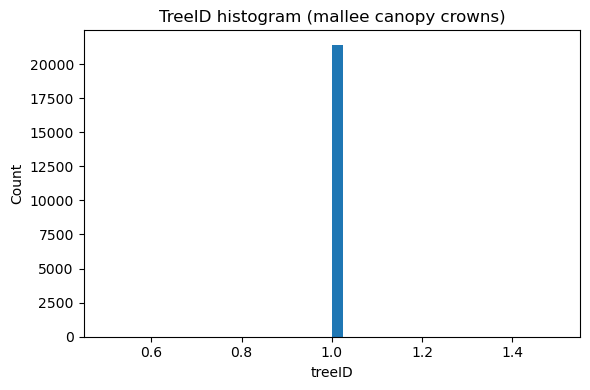

In [8]:
# --- Inspect final output: classes + treeID ---

las_out = laspy.read(out_full)
cls = np.asarray(las_out.classification, dtype=np.uint8)
zn_out = np.asarray(las_out["Z_norm"], dtype=float)
tree_ids = np.asarray(las_out["treeID"], dtype=np.uint16)

# Class distribution
unique, counts = np.unique(cls, return_counts=True)
print("Class distribution in output:")
for u, c in zip(unique, counts):
    pct = 100.0 * c / len(cls)
    print(f"  Class {u:3d}: {c:8d} pts ({pct:5.1f} %)")

# TreeID histogram (mallee canopy only, by design)
valid_trees = tree_ids[tree_ids > 0]
if valid_trees.size > 0:
    plt.figure(figsize=(6, 4))
    plt.hist(valid_trees, bins=40)
    plt.xlabel("treeID")
    plt.ylabel("Count")
    plt.title("TreeID histogram (mallee canopy crowns)")
    plt.tight_layout()
    plt.show()
else:
    print("No non-zero treeIDs in this tile (check thresholds / watershed).")


In [9]:
# --- Diagnostic: Check LAS file integrity and bounds ---

las_out = laspy.read(out_full)
print(f"Total points: {len(las_out.points):,}")
print(f"\nBounding box:")
print(f"  X: {las_out.header.mins[0]:.2f} → {las_out.header.maxs[0]:.2f} (range: {las_out.header.maxs[0] - las_out.header.mins[0]:.2f} m)")
print(f"  Y: {las_out.header.mins[1]:.2f} → {las_out.header.maxs[1]:.2f} (range: {las_out.header.maxs[1] - las_out.header.mins[1]:.2f} m)")
print(f"  Z: {las_out.header.mins[2]:.2f} → {las_out.header.maxs[2]:.2f} (range: {las_out.header.maxs[2] - las_out.header.mins[2]:.2f} m)")

print(f"\nPoint format: {las_out.header.point_format}")
print(f"Extra dimensions: {[dim.name for dim in las_out.point_format.extra_dimensions]}")

# Check for any extreme coordinate values
x_vals = las_out.x
y_vals = las_out.y
z_vals = las_out.z

print(f"\nActual coordinate ranges:")
print(f"  X: {x_vals.min():.2f} → {x_vals.max():.2f}")
print(f"  Y: {y_vals.min():.2f} → {y_vals.max():.2f}")
print(f"  Z: {z_vals.min():.2f} → {z_vals.max():.2f}")

# Check for NaN or infinite values
invalid_x = np.isnan(x_vals) | np.isinf(x_vals)
invalid_y = np.isnan(y_vals) | np.isinf(y_vals)
invalid_z = np.isnan(z_vals) | np.isinf(z_vals)

if invalid_x.any() or invalid_y.any() or invalid_z.any():
    print(f"\n⚠️  WARNING: Found invalid coordinates:")
    print(f"  Invalid X: {invalid_x.sum():,}")
    print(f"  Invalid Y: {invalid_y.sum():,}")
    print(f"  Invalid Z: {invalid_z.sum():,}")
else:
    print(f"\n✅ All coordinates are valid (no NaN/Inf values)")

Total points: 640,386

Bounding box:
  X: 473254.13 → 473284.81 (range: 30.68 m)
  Y: 6235802.84 → 6235833.56 (range: 30.72 m)
  Z: 33.19 → 40.30 (range: 7.11 m)

Point format: <PointFormat(7, 6 bytes of extra dims)>
Extra dimensions: ['Z_norm', 'treeID']

Actual coordinate ranges:
  X: 473254.13 → 473284.81
  Y: 6235802.84 → 6235833.56
  Z: 33.19 → 40.30

✅ All coordinates are valid (no NaN/Inf values)


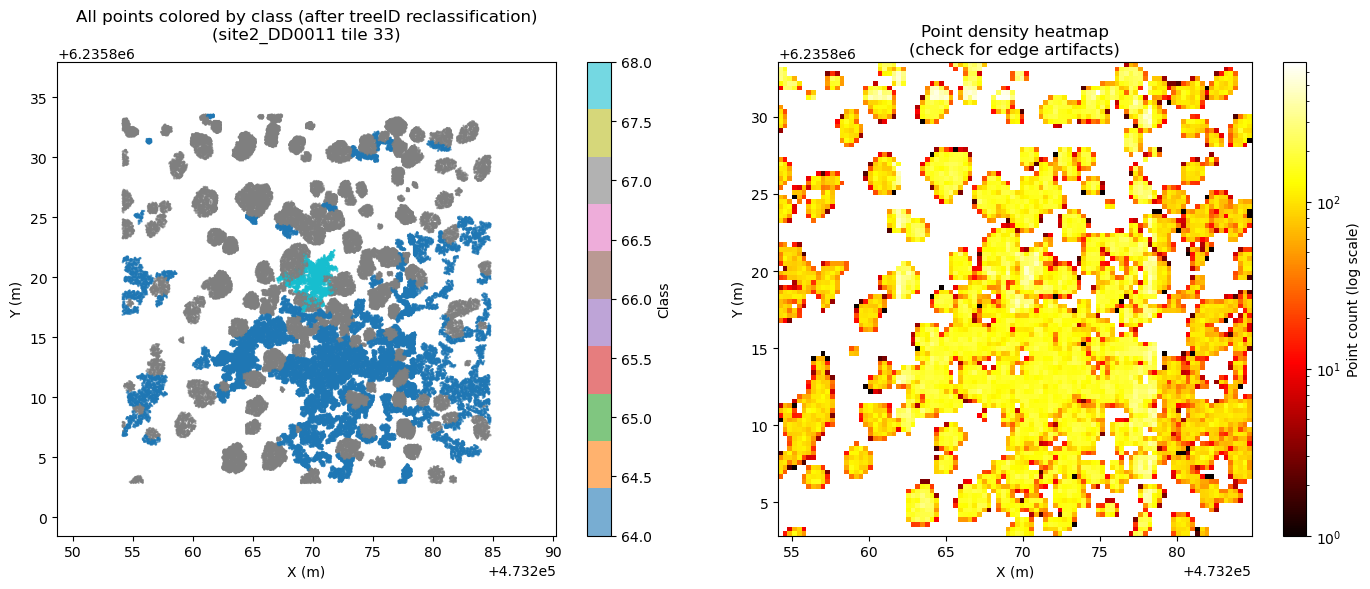


Points near boundaries (within 1% of range):
  Near X min: 3,972 (0.62%)
  Near X max: 2,887 (0.45%)
  Near Y min: 2,306 (0.36%)
  Near Y max: 2,416 (0.38%)


In [10]:
# --- Visualize point distribution to check boundary issues ---

cls = np.asarray(las_out.classification, dtype=np.uint8)
zn_out = np.asarray(las_out["Z_norm"], dtype=float)
tree_ids = np.asarray(las_out["treeID"], dtype=np.uint16)

# Reclassify points with treeID to mallee (68)
has_treeid = tree_ids > 0
before_reclass = cls.copy()
cls[has_treeid] = 68

n_reclassified = (before_reclass != cls).sum()
if n_reclassified > 0:
    print(f"🔄 Reclassified {n_reclassified:,} points to class 68 (mallee) based on treeID")
    class_changes = {}
    for old_cls in np.unique(before_reclass[before_reclass != cls]):
        count = ((before_reclass == old_cls) & (cls == 68)).sum()
        class_changes[old_cls] = count
    for old_cls, count in sorted(class_changes.items()):
        print(f"  Class {old_cls} → 68: {count:,} points")

# Subsample for plotting if too many points
subsample_mask = np.ones(len(las_out.points), dtype=bool)
if len(las_out.points) > 100000:
    subsample_idx = np.random.choice(len(las_out.points), size=100000, replace=False)
    subsample_mask = np.zeros(len(las_out.points), dtype=bool)
    subsample_mask[subsample_idx] = True

x_sub = x_vals[subsample_mask]
y_sub = y_vals[subsample_mask]
cls_sub = cls[subsample_mask]

# Plot all points colored by class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: All points by class
sc1 = axes[0].scatter(x_sub, y_sub, c=cls_sub, s=0.5, cmap="tab10", alpha=0.6)
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].set_title(f"All points colored by class (after treeID reclassification)\n({SITE_NAME} tile {tile_id})")
axes[0].set_aspect('equal', adjustable='datalim')
plt.colorbar(sc1, ax=axes[0], label="Class")

# Right: Boundary check - show point density
from matplotlib.colors import LogNorm
h, xedges, yedges = np.histogram2d(x_vals, y_vals, bins=100)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
im = axes[1].imshow(h.T, extent=extent, origin='lower', cmap='hot', 
                     norm=LogNorm(vmin=max(1, h[h>0].min()), vmax=h.max()))
axes[1].set_xlabel("X (m)")
axes[1].set_ylabel("Y (m)")
axes[1].set_title("Point density heatmap\n(check for edge artifacts)")
axes[1].set_aspect('equal', adjustable='box')
plt.colorbar(im, ax=axes[1], label="Point count (log scale)")

plt.tight_layout()
plt.show()

# Check for points clustered at boundaries
x_range = x_vals.max() - x_vals.min()
y_range = y_vals.max() - y_vals.min()
x_min, x_max = x_vals.min(), x_vals.max()
y_min, y_max = y_vals.min(), y_vals.max()

# Count points near edges (within 1% of range)
edge_thresh_x = x_range * 0.01
edge_thresh_y = y_range * 0.01

near_x_min = (x_vals < x_min + edge_thresh_x).sum()
near_x_max = (x_vals > x_max - edge_thresh_x).sum()
near_y_min = (y_vals < y_min + edge_thresh_y).sum()
near_y_max = (y_vals > y_max - edge_thresh_y).sum()

print(f"\nPoints near boundaries (within 1% of range):")
print(f"  Near X min: {near_x_min:,} ({100*near_x_min/len(x_vals):.2f}%)")
print(f"  Near X max: {near_x_max:,} ({100*near_x_max/len(x_vals):.2f}%)")
print(f"  Near Y min: {near_y_min:,} ({100*near_y_min/len(y_vals):.2f}%)")
print(f"  Near Y max: {near_y_max:,} ({100*near_y_max/len(y_vals):.2f}%)")

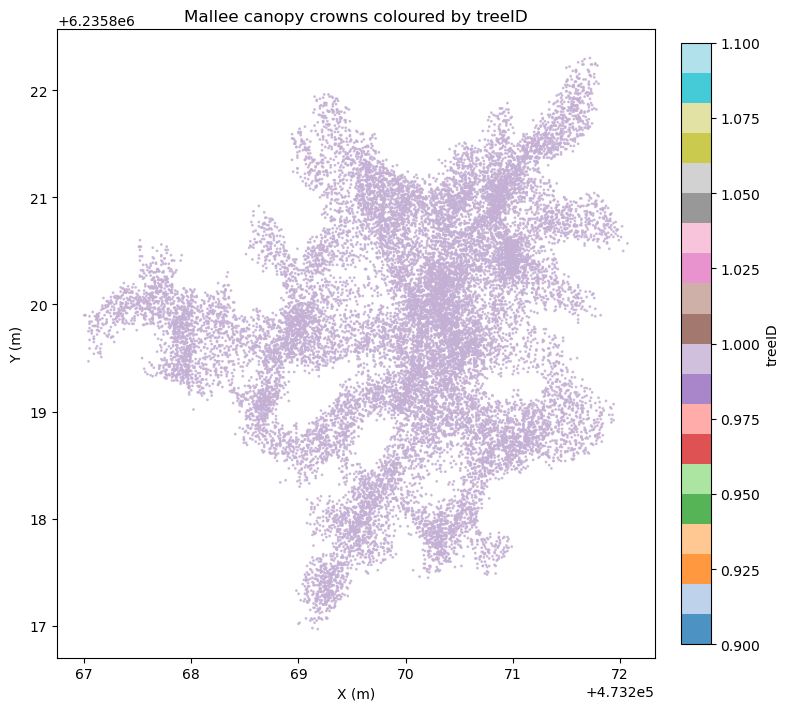

Displayed 21,400 mallee crown points
TreeID range: 1 → 1


In [11]:
# --- Quick 2D scatter: mallee crowns only ---

is_mallee = cls == 68
has_tree = tree_ids > 0
mask_mallee_crown = is_mallee & has_tree

subsample = mask_mallee_crown
if subsample.sum() > 80000:
    # random subsample for plotting
    idx = np.where(mask_mallee_crown)[0]
    choice = np.random.choice(idx, size=80000, replace=False)
    subsample = np.zeros_like(mask_mallee_crown)
    subsample[choice] = True

if subsample.any():
    xs = las_out.x[subsample]
    ys = las_out.y[subsample]
    tids = tree_ids[subsample]

    fig, ax = plt.subplots(figsize=(8, 8))
    sc = ax.scatter(xs, ys, c=tids, s=1, cmap="tab20", alpha=0.8)
    ax.set_title("Mallee canopy crowns coloured by treeID", fontsize=12)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect('equal', adjustable='box')
    plt.colorbar(sc, ax=ax, label="treeID", fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()
    
    print(f"Displayed {subsample.sum():,} mallee crown points")
    print(f"TreeID range: {tids.min()} → {tids.max()}")
else:
    print("No mallee canopy crown points to scatter-plot in this tile.")

Found 1 unique treeIDs: [1]
  TreeID 1: 21,400 points (3.3%)


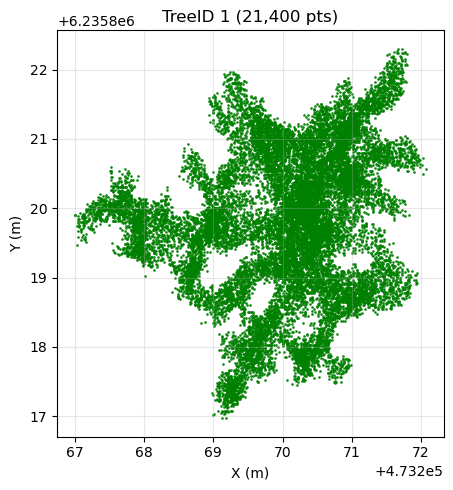

In [12]:
# --- Diagnostic: Analyze treeID spatial distribution ---

if tree_ids.max() > 0:
    unique_tids = np.unique(tree_ids[tree_ids > 0])
    print(f"Found {len(unique_tids)} unique treeIDs: {unique_tids}")
    
    # Show point count per treeID
    for tid in unique_tids:
        count = np.sum(tree_ids == tid)
        pct = 100.0 * count / len(tree_ids)
        print(f"  TreeID {tid}: {count:,} points ({pct:.1f}%)")
    
    # Plot separate trees side-by-side
    n_trees = len(unique_tids)
    ncols = min(3, n_trees)
    nrows = (n_trees + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows), squeeze=False)
    axes = axes.flatten()
    
    for i, tid in enumerate(unique_tids):
        mask = tree_ids == tid
        if mask.sum() > 0:
            xs = las_out.x[mask]
            ys = las_out.y[mask]
            
            axes[i].scatter(xs, ys, c='green', s=1, alpha=0.8)
            axes[i].set_title(f"TreeID {tid} ({mask.sum():,} pts)")
            axes[i].set_xlabel("X (m)")
            axes[i].set_ylabel("Y (m)")
            axes[i].set_aspect('equal', adjustable='box')
            axes[i].grid(True, alpha=0.3)
    
    # Hide unused subplots
    for i in range(n_trees, len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    if len(unique_tids) > 1:
        print("\n💡 If these should be merged into fewer trees:")
        print("   1. Go back to cell 6 (exploratory watershed)")
        print("   2. Increase min_tree_dist (try 2.0, 2.5, or 3.0m)")
        print("   3. When satisfied, copy those parameters to cell 8 config")
        print("   4. Re-run cells 2 (cache clear) and 8 (pipeline)")
else:
    print("No treeIDs to analyze.")